In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/paresh2047/uci-semcom/uci-secom.csv
/kaggle/input/datasets/qingyi/wm811k-wafer-map/LSWMD.pkl


In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/paresh2047/uci-semcom/uci-secom.csv
/kaggle/input/datasets/qingyi/wm811k-wafer-map/LSWMD.pkl


In [3]:
import pandas as pd
import pickle

# ==========================
# Load SECOM Dataset
# ==========================

secom_df = pd.read_csv("/kaggle/input/datasets/paresh2047/uci-semcom/uci-secom.csv")

print("SECOM Shape - physical factors:", secom_df.shape)
print(secom_df.head())


# ==========================
# Load WM-811K Dataset
# ==========================
print("WM-811K Dataset - Containing defects patterns")
wafer_df = pd.read_pickle(
    "/kaggle/input/datasets/qingyi/wm811k-wafer-map/LSWMD.pkl"
)

print(wafer_df.shape)
wafer_df.head()

SECOM Shape - physical factors: (1567, 592)
                  Time        0        1          2          3       4      5  \
0  2008-07-19 11:55:00  3030.93  2564.00  2187.7333  1411.1265  1.3602  100.0   
1  2008-07-19 12:32:00  3095.78  2465.14  2230.4222  1463.6606  0.8294  100.0   
2  2008-07-19 13:17:00  2932.61  2559.94  2186.4111  1698.0172  1.5102  100.0   
3  2008-07-19 14:43:00  2988.72  2479.90  2199.0333   909.7926  1.3204  100.0   
4  2008-07-19 15:22:00  3032.24  2502.87  2233.3667  1326.5200  1.5334  100.0   

          6       7       8  ...       581     582     583     584      585  \
0   97.6133  0.1242  1.5005  ...       NaN  0.5005  0.0118  0.0035   2.3630   
1  102.3433  0.1247  1.4966  ...  208.2045  0.5019  0.0223  0.0055   4.4447   
2   95.4878  0.1241  1.4436  ...   82.8602  0.4958  0.0157  0.0039   3.1745   
3  104.2367  0.1217  1.4882  ...   73.8432  0.4990  0.0103  0.0025   2.0544   
4  100.3967  0.1235  1.5031  ...       NaN  0.4800  0.4766  0.1045  99.303

,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]


In [4]:
total_missing = secom_df.isnull().sum().sum()
missing_percentage = secom_df.isnull().mean() * 100

high_missing = missing_percentage[
    missing_percentage > 50
]
print(total_missing)
print(len(high_missing))

print("------------------------------------------------------------")

print(secom_df["Pass/Fail"].value_counts())
print(secom_df["Pass/Fail"].value_counts(normalize=True) * 100)

41951
28
------------------------------------------------------------
Pass/Fail
-1    1463
 1     104
Name: count, dtype: int64
Pass/Fail
-1    93.363114
 1     6.636886
Name: proportion, dtype: float64


In [5]:
# Calculate missing percentage
missing_percentage = secom_df.isnull().mean() * 100

# Find columns with >50% missing values
cols_to_drop = missing_percentage[
    missing_percentage > 50
].index

print("Columns to remove:", len(cols_to_drop))

# Remove them
secom_cleaned = secom_df.drop(
    columns=cols_to_drop
)

print("Original Shape:", secom_df.shape)
print("Cleaned Shape:", secom_cleaned.shape)

Columns to remove: 28
Original Shape: (1567, 592)
Cleaned Shape: (1567, 564)


In [6]:
row_missing_percent = secom_df.isnull().mean(axis=1) * 100

print(row_missing_percent.describe())

print(
    "Rows with >50% missing:",
    (row_missing_percent > 50).sum()
)

count    1567.000000
mean        4.522219
std         2.259716
min         0.675676
25%         3.378378
50%         4.054054
75%         5.405405
max        25.675676
dtype: float64
Rows with >50% missing: 0


Columns:
Index(['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel',
       'failureType'],
      dtype='object')

First Row:
waferMap          [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...
dieSize                                                      1683.0
lotName                                                        lot1
waferIndex                                                      1.0
trianTestLabel                                         [[Training]]
failureType                                                [[none]]
Name: 0, dtype: object

Wafer Map Type: <class 'numpy.ndarray'>
Wafer Map Shape: (45, 48)



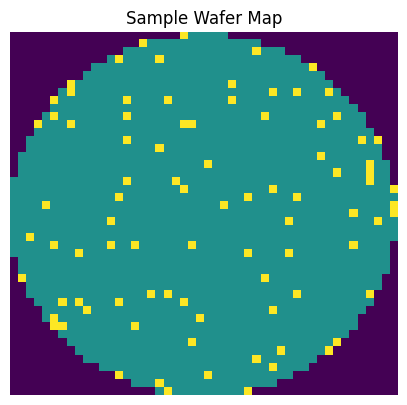


Failure Type Counts:
failureLabel
Unknown      638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64



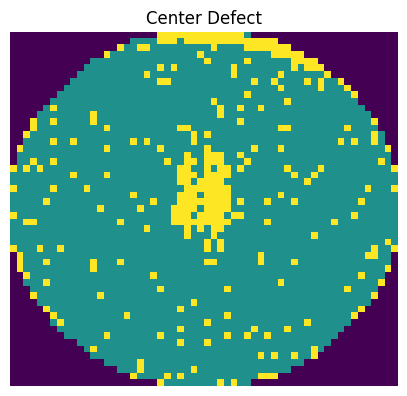

In [7]:
# import pandas as pd
# import numpy as np
import matplotlib.pyplot as plt

# ====================================
# Dataset Overview
# ====================================

print("Columns:")
print(wafer_df.columns)

print("\nFirst Row:")
print(wafer_df.iloc[0])

print("\n" + "="*50)

# ====================================
# Inspect One Wafer Map
# ====================================

sample_map = wafer_df.iloc[0]["waferMap"]

print("Wafer Map Type:", type(sample_map))
print("Wafer Map Shape:", sample_map.shape)

print("\n" + "="*50)

# ====================================
# Display Sample Wafer
# ====================================

plt.figure(figsize=(5,5))
plt.imshow(sample_map)
plt.title("Sample Wafer Map")
plt.axis("off")
plt.show()

print("\n" + "="*50)

# ====================================
# Extract Failure Labels Safely
# ====================================

def extract_failure_type(x):
    try:
        if len(x) > 0:
            return x[0][0]
        else:
            return "Unknown"
    except:
        return "Unknown"

wafer_df["failureLabel"] = wafer_df["failureType"].apply(
    extract_failure_type
)

print("Failure Type Counts:")
print(wafer_df["failureLabel"].value_counts())

print("\n" + "="*50)

# ====================================
# Display One Center Defect Example
# ====================================

center_rows = wafer_df[
    wafer_df["failureLabel"] == "Center"
]

if len(center_rows) > 0:

    center_map = center_rows.iloc[0]["waferMap"]

    plt.figure(figsize=(5,5))
    plt.imshow(center_map)
    plt.title("Center Defect")
    plt.axis("off")
    plt.show()

else:
    print("No Center defect found.")

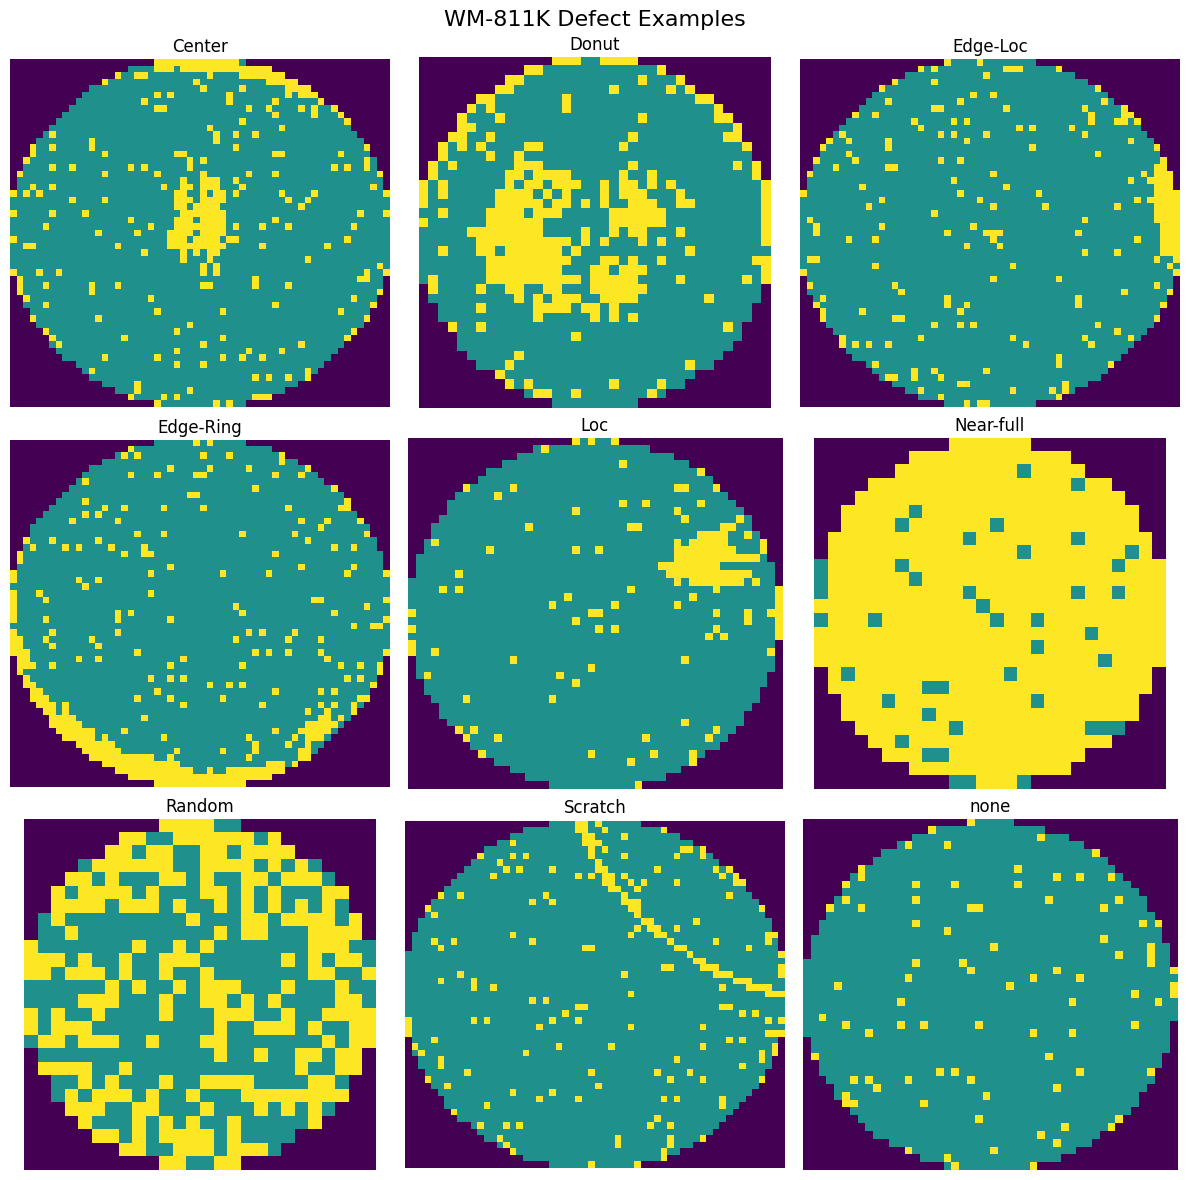

In [8]:
# import matplotlib.pyplot as plt

# Defect classes to display
defect_classes = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch",
    "none"
]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, defect in zip(axes.flatten(), defect_classes):

    sample = wafer_df[
        wafer_df["failureLabel"] == defect
    ].iloc[0]

    wafer_map = sample["waferMap"]

    ax.imshow(wafer_map)

    ax.set_title(defect)

    ax.axis("off")

plt.suptitle(
    "WM-811K Defect Examples",
    fontsize=16
)

plt.tight_layout()

plt.show()